EDA:Exploratory Data Analysis 
tHis is the stage where we explore the given data like columns, dat apoints etc.
Idea:  what ar ethe features are therir to determine the output value.
Feature extraction is important here to get perfect output

ML algo is not capable of detecting which feature is important and which are not unlike deeplearning. So we need to explore every column of input data. ANd only important feature(colum) shdbe provided to model to get better accuracy. So, eda step is important.ML is very good for samll size of dataset as well unlike deeplearning required hughe data.

we can dtect outliers, also validatating our assumption like say we have dataset and assumed that women survied more than men in one trajedy



# Steps for EDA

### Categorise the given column as a numerical . categorical or mixed dats type column
### univariate analysis ----? numerical or categorical col

### numerical colum analysis ---> Distribution of the data ---> histogram plot, kdeplot
    ### figure out outliers for numerical col ---> use box plot ---> use mean, median imputation
    ### figure out handle missing values 

### Categotival colum anlaysis --? Distribution of the data --> use countplot
    ### Handle missing value in categorical col---> use mode,most frequrnt imputaion


### Bivariate analysis --> 
    ### Numerical numerical colu ---> use scatter plot
    ### numerical categorical colum --> barplot
    ### Categorical categorical colum ---> heatmap

### EDA ---> must need to pass this EDA for Feature engineering step



In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('tested.csv') # titanic dataset

In [3]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [4]:
### Categorise the given column as a numerical . categorical or mixed dats type column

# univariate analysis on numerical colum
# data distribution of the numerical colum -->  use describe() and for plotting use kde or histogram
# outlierdetcetion --> use box plot,
# if required then only go to imputaion step(data clening) else skip

df['Age'].describe()

count    332.000000
mean      30.272590
std       14.181209
min        0.170000
25%       21.000000
50%       27.000000
75%       39.000000
max       76.000000
Name: Age, dtype: float64

In [5]:
df[df['Age']==76]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
96,988,1,1,"Cavendish, Mrs. Tyrell William (Julia Florence...",female,76.0,1,0,19877,78.85,C46,S


<Axes: xlabel='Age'>

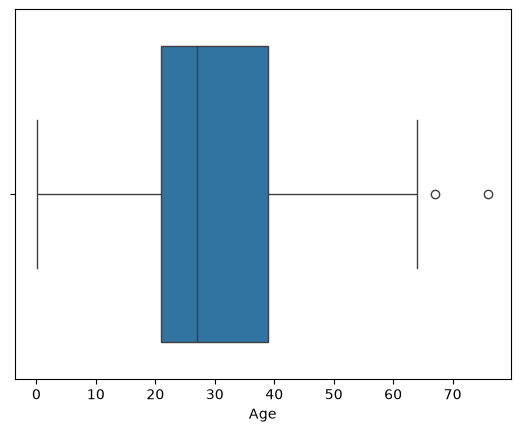

In [6]:
# to find the real outlier go with box plot
sns.boxplot(data=df,x='Age')

# here we see 2 ppl have age 65 and 76 which w ecannot tell as outlier as is because its true data do still if we want to do datcleaning means imputation we can go with nedian value instaed of mean. Befor ethat we check teh missing data.

In [7]:
# find any missing  values
df['Age'].isnull().sum()

np.int64(86)

In [8]:
# we see 86 missing dats so teh impuation step is rewuired here. will go with median
df['Age']=df['Age'].fillna(df['Age'].median())

In [9]:
df['Age'].isnull().sum()

np.int64(0)

In [10]:
df['Age'].describe()

count    418.000000
mean      29.599282
std       12.703770
min        0.170000
25%       23.000000
50%       27.000000
75%       35.750000
max       76.000000
Name: Age, dtype: float64

<Axes: xlabel='Age', ylabel='Count'>

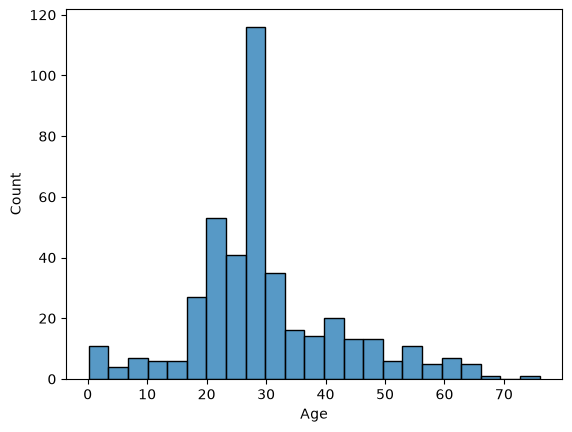

In [11]:
# using grapgical way 
sns.histplot(data=df,x='Age')

<Axes: xlabel='Age', ylabel='Density'>

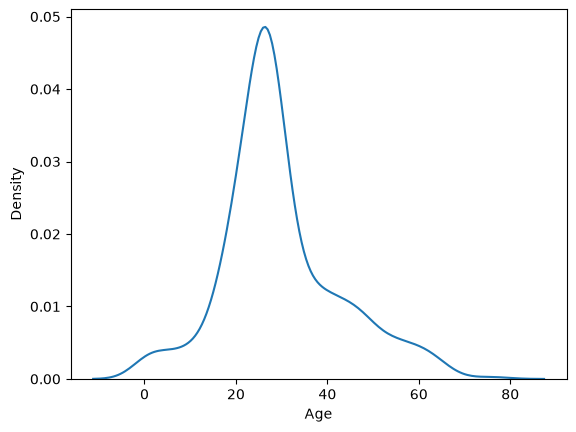

In [12]:
sns.kdeplot(data=df,x= 'Age')

#insight form the plots an dabove analysis, we see max age gp lies between 18 to 40 years

In [13]:
df.shape

(418, 12)

In [14]:
df['Fare'].describe()

count    417.000000
mean      35.627188
std       55.907576
min        0.000000
25%        7.895800
50%       14.454200
75%       31.500000
max      512.329200
Name: Fare, dtype: float64

In [15]:
df[df['Fare']==512.329200]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
343,1235,1,1,"Cardeza, Mrs. James Warburton Martinez (Charlo...",female,58.0,0,1,PC 17755,512.3292,B51 B53 B55,C


In [16]:
df[df['Ticket']=='PC 17755']['Name']

343    Cardeza, Mrs. James Warburton Martinez (Charlo...
Name: Name, dtype: str

<Axes: xlabel='Fare'>

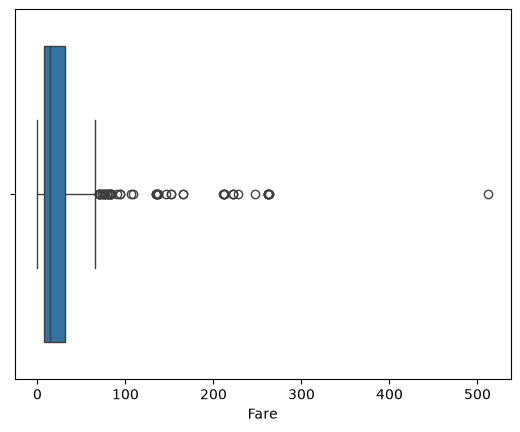

In [17]:
sns.boxplot(data=df,x='Fare')

<Axes: xlabel='Fare', ylabel='Count'>

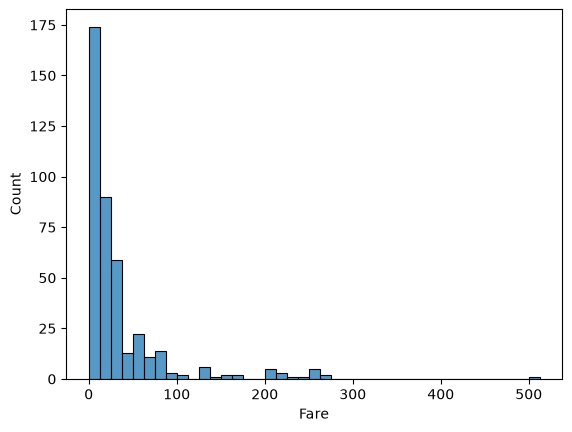

In [18]:
sns.histplot(data=df,x = 'Fare')

# insight we see her emost of teh people are poor and few are rich

In [19]:
# Univariate nalaysis for categotical col
# data distobution --> use value_counts()--> use countplot()
# Handle missing value-->mode or most frequent value
df['Survived'].value_counts()

Survived
0    266
1    152
Name: count, dtype: int64

<Axes: xlabel='Survived', ylabel='count'>

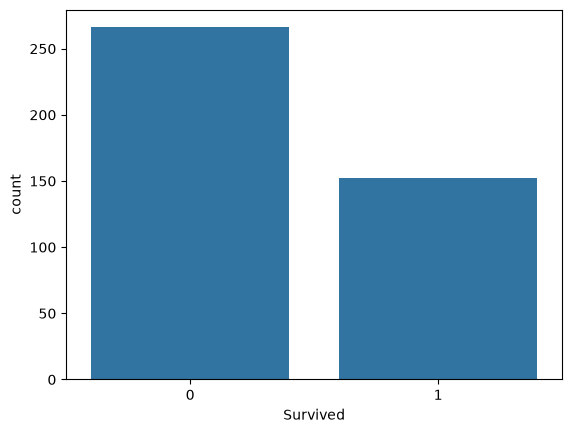

In [20]:
sns.countplot(data= df,x ='Survived')

In [21]:
df['Survived'].isnull().sum()

np.int64(0)

In [22]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [23]:
df['Embarked'].value_counts()

Embarked
S    270
C    102
Q     46
Name: count, dtype: int64

<Axes: xlabel='Embarked', ylabel='Count'>

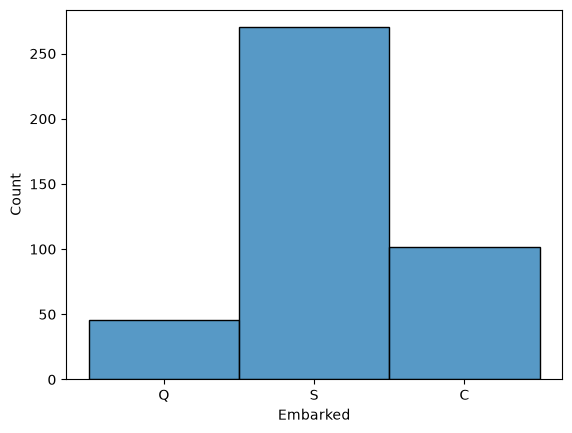

In [24]:
sns.histplot(data=df,x = 'Embarked')

In [25]:
# Bivaiate colum analysis
df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


<Axes: xlabel='Age', ylabel='Fare'>

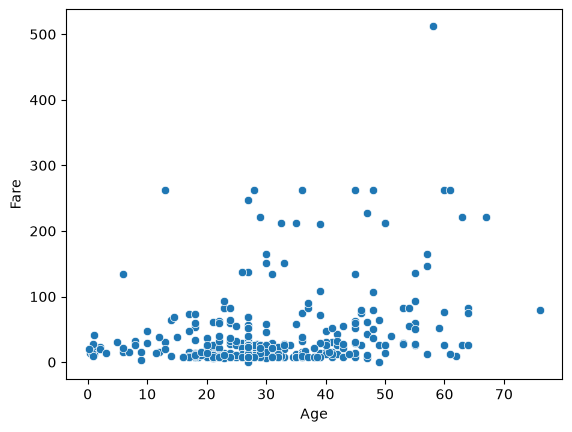

In [26]:
# numerical numerical colum
sns.scatterplot(data=df,x='Age',y='Fare')

<Axes: xlabel='Pclass', ylabel='Fare'>

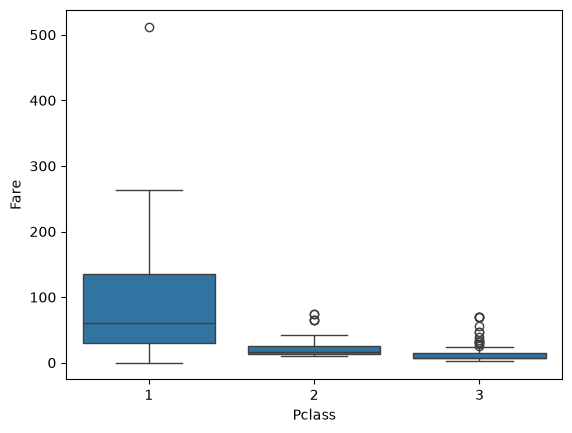

In [27]:
# numerical categorical colum
sns.boxplot(data=df,x='Pclass',y='Fare')

<Axes: xlabel='Embarked', ylabel='Fare'>

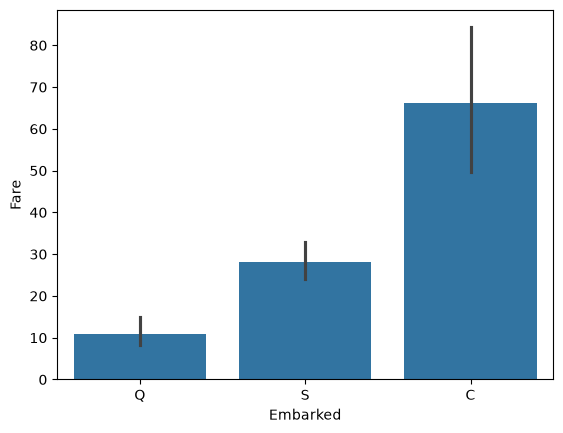

In [ ]:
sns.barplot(data=df,x='Embarked',y='Fare')

In [29]:
df['SibSp'].value_counts()

SibSp
0    283
1    110
2     14
3      4
4      4
8      2
5      1
Name: count, dtype: int64

<Axes: xlabel='SibSp', ylabel='Fare'>

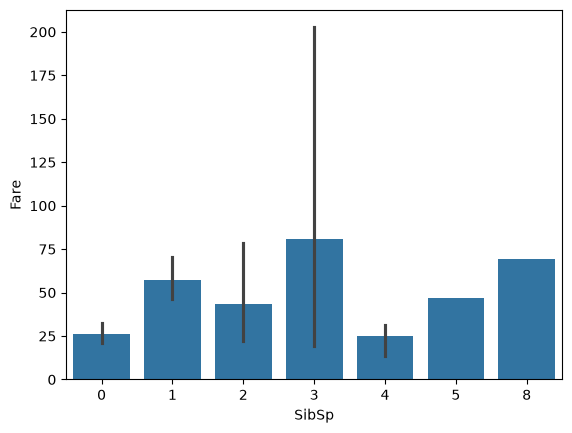

In [31]:
sns.barplot(data=df,x='SibSp',y='Fare')

<Axes: xlabel='Sex', ylabel='Fare'>

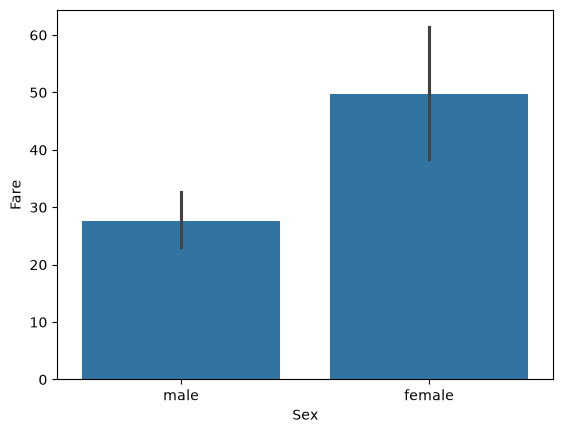

In [32]:
sns.barplot(data=df,x='Sex',y='Fare')

In [38]:
# catergorical categorical column analysis
# use crosstab() function -->  categories as input  on which we can perform the anlaysis
pd.crosstab(df['Pclass'],df['Survived'])

Survived,0,1
Pclass,,
1,57,50
2,63,30
3,146,72


In [43]:
pd.crosstab(df['Pclass'],df['Survived'],normalize=True)*100

Survived,0,1
Pclass,,
1,13.636364,11.961722
2,15.071770,7.177033
3,34.928230,17.224880


<Axes: xlabel='Survived', ylabel='Pclass'>

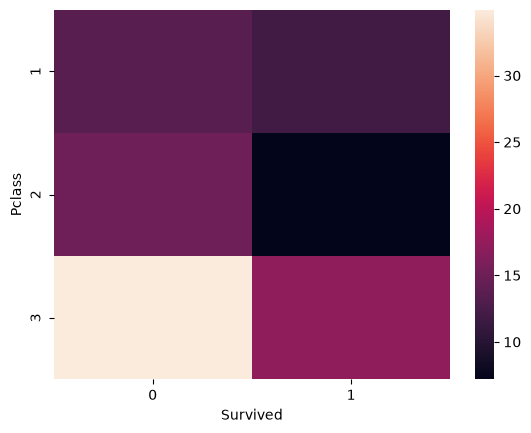

In [45]:
sns.heatmap(pd.crosstab(df['Pclass'],df['Survived'],normalize=True)*100) 

In [48]:
#pd.crosstab(df['Sex'],df['Survived'],normalize =True)
pd.crosstab(df['Sex'],df['Survived'])

Survived,0,1
Sex,,
female,0,152
male,266,0


In [47]:
df['Sex'].value_counts()

Sex
male      266
female    152
Name: count, dtype: int64

In [51]:
pd.crosstab(df['Sex'],df['Survived'],normalize =True)

Survived,0,1
Sex,,
female,0.000000,0.363636
male,0.636364,0.000000


<Axes: xlabel='Survived', ylabel='Sex'>

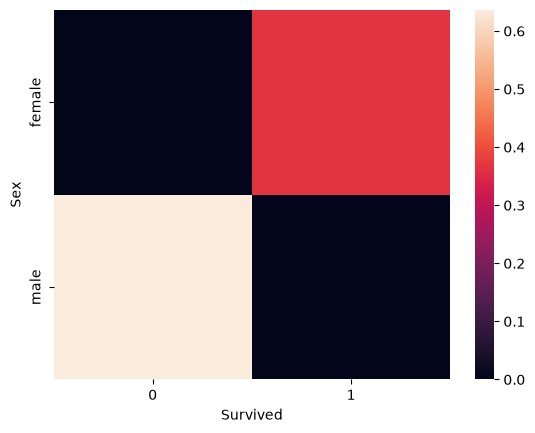

In [52]:
sns.heatmap(pd.crosstab(df['Sex'],df['Survived'],normalize =True))